In [ ]:
!pip install xgboost

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving sales_data.csv to sales_data.csv


In [ ]:
import pandas as pd

df = pd.read_csv('sales_data.csv')

print(df.head())
print(df.columns)

         date       Sales
0  2020-01-01  104.967142
1  2020-02-01  126.474500
2  2020-03-01  155.492441
3  2020-04-01  173.801727
4  2020-05-01  152.388308
Index(['date', 'Sales'], dtype='object')


MAE : 22.09
RMSE: 26.33
MAPE: 13.15 %


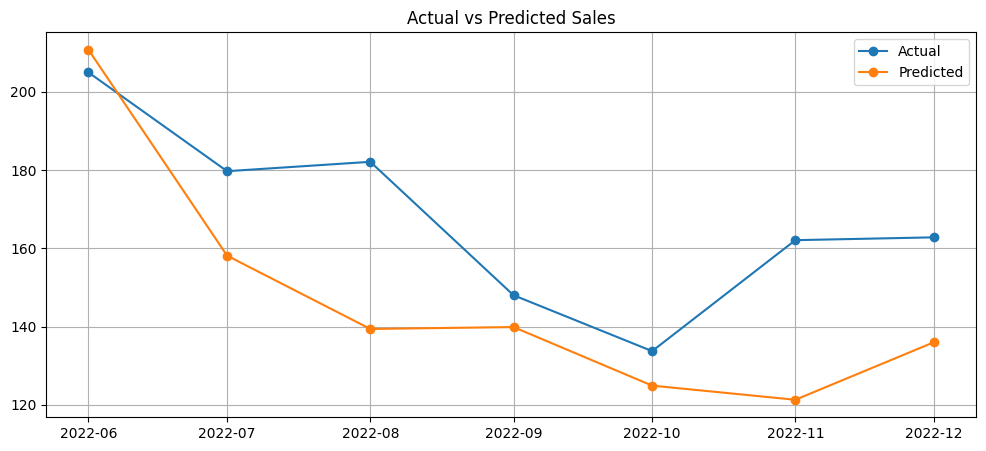


Future Forecast:
        Date  Forecasted_Sales
0 2023-01-01        170.064072
1 2023-02-01        196.376434
2 2023-03-01        197.791412
3 2023-04-01        206.466125
4 2023-05-01        215.645096
5 2023-06-01        210.731110


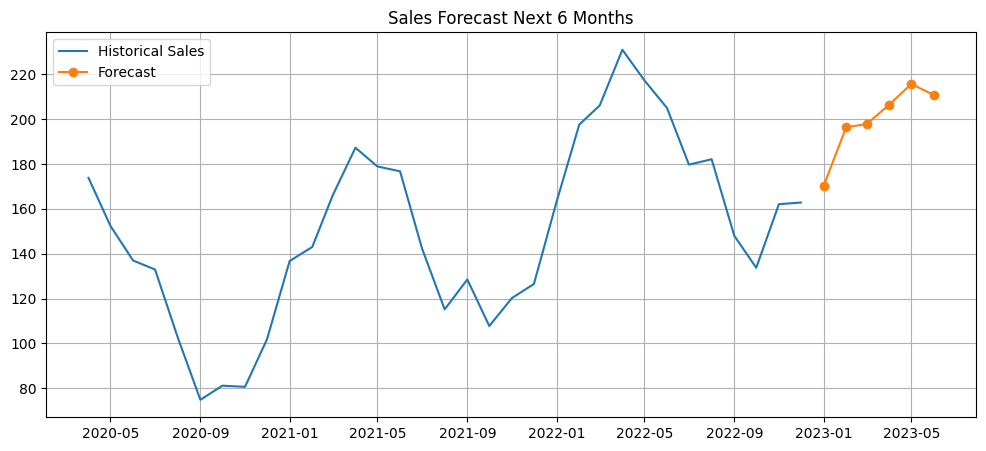

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_percentage_error
from xgboost import XGBRegressor

# Load Data
df = pd.read_csv('sales_data.csv')

# Correct column names
DATE_COL = 'date'
SALES_COL = 'Sales'

# Convert date column
df[DATE_COL] = pd.to_datetime(df[DATE_COL])

# Sort data
df = df.sort_values(DATE_COL)

# Feature Engineering
df['year'] = df[DATE_COL].dt.year
df['month'] = df[DATE_COL].dt.month
df['quarter'] = df[DATE_COL].dt.quarter

df['lag1'] = df[SALES_COL].shift(1)
df['lag3'] = df[SALES_COL].shift(3)

df['rolling3'] = df[SALES_COL].rolling(3).mean()

df.dropna(inplace=True)

# Train-Test Split
split = int(len(df)*0.8)

train = df.iloc[:split]
test = df.iloc[split:]

features = [
    'year',
    'month',
    'quarter',
    'lag1',
    'lag3',
    'rolling3'
]

X_train = train[features]
y_train = train[SALES_COL]

X_test = test[features]
y_test = test[SALES_COL]

# Model
model = XGBRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

model.fit(X_train, y_train)

pred = model.predict(X_test)

# Evaluation
mae = mean_absolute_error(y_test, pred)
rmse = np.sqrt(mean_squared_error(y_test, pred))
mape = mean_absolute_percentage_error(y_test, pred)*100

print("MAE :", round(mae,2))
print("RMSE:", round(rmse,2))
print("MAPE:", round(mape,2), "%")

# Actual vs Predicted Plot
plt.figure(figsize=(12,5))
plt.plot(test[DATE_COL], y_test, marker='o', label='Actual')
plt.plot(test[DATE_COL], pred, marker='o', label='Predicted')
plt.title('Actual vs Predicted Sales')
plt.legend()
plt.grid(True)
plt.show()

# Future Forecast - Next 6 Months
future_dates = pd.date_range(
    start=df[DATE_COL].max() + pd.offsets.MonthBegin(1),
    periods=6,
    freq='MS'
)

future_sales = []

last_sales = df[SALES_COL].tolist()

for d in future_dates:

    lag1 = last_sales[-1]
    lag3 = last_sales[-3]
    rolling3 = np.mean(last_sales[-3:])

    row = pd.DataFrame({
        'year':[d.year],
        'month':[d.month],
        'quarter':[d.quarter],
        'lag1':[lag1],
        'lag3':[lag3],
        'rolling3':[rolling3]
    })

    forecast = model.predict(row)[0]

    future_sales.append(forecast)
    last_sales.append(forecast)

forecast_df = pd.DataFrame({
    'Date': future_dates,
    'Forecasted_Sales': future_sales
})

print("\nFuture Forecast:")
print(forecast_df)

# Forecast Plot
plt.figure(figsize=(12,5))
plt.plot(df[DATE_COL], df[SALES_COL], label='Historical Sales')
plt.plot(forecast_df['Date'],
         forecast_df['Forecasted_Sales'],
         marker='o',
         label='Forecast')
plt.title('Sales Forecast Next 6 Months')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
!pip install plotly

In [ ]:
import plotly.express as px
import plotly.graph_objects as go

# Historical Sales Dashboard

fig1 = px.line(
    df,
    x='date',
    y='Sales',
    title='Historical Sales Trend'
)
fig1.show()

# Actual vs Predicted

results = pd.DataFrame({
    'Date': test['date'],
    'Actual': y_test,
    'Predicted': pred
})

fig2 = go.Figure()

fig2.add_trace(
    go.Scatter(
        x=results['Date'],
        y=results['Actual'],
        mode='lines+markers',
        name='Actual'
    )
)

fig2.add_trace(
    go.Scatter(
        x=results['Date'],
        y=results['Predicted'],
        mode='lines+markers',
        name='Predicted'
    )
)

fig2.update_layout(
    title='Actual vs Predicted Sales'
)

fig2.show()

# Future Forecast

fig3 = go.Figure()

fig3.add_trace(
    go.Scatter(
        x=df['date'],
        y=df['Sales'],
        mode='lines',
        name='Historical'
    )
)

fig3.add_trace(
    go.Scatter(
        x=forecast_df['Date'],
        y=forecast_df['Forecasted_Sales'],
        mode='lines+markers',
        name='Forecast'
    )
)

fig3.update_layout(
    title='Future Sales Forecast'
)

fig3.show()

In [ ]:
!pip install streamlit pyngrok


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 42.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 85.3 MB/s eta 0:00:00


In [ ]:
from pyngrok import ngrok


In [ ]:
!streamlit run app.py &>/content/logs.txt &

In [ ]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

fig = make_subplots(
    rows=2, cols=2,
    subplot_titles=(
        "Historical Sales",
        "Actual vs Predicted",
        "Future Forecast",
        "Sales Distribution"
    )
)

fig.add_trace(
    go.Scatter(x=df['date'], y=df['Sales'],
               mode='lines+markers',
               name='Sales'),
    row=1, col=1
)

fig.add_trace(
    go.Scatter(x=test['date'], y=y_test,
               mode='lines+markers',
               name='Actual'),
    row=1, col=2
)

fig.add_trace(
    go.Scatter(x=test['date'], y=pred,
               mode='lines+markers',
               name='Predicted'),
    row=1, col=2
)

fig.add_trace(
    go.Scatter(
        x=forecast_df['Date'],
        y=forecast_df['Forecasted_Sales'],
        mode='lines+markers',
        name='Forecast'
    ),
    row=2, col=1
)

fig.add_trace(
    go.Histogram(
        x=df['Sales'],
        name='Distribution'
    ),
    row=2, col=2
)

fig.update_layout(
    height=800,
    width=1200,
    title="Sales Forecasting Dashboard"
)

fig.show()

In [ ]:
print("MAE :", round(mae,2))
print("RMSE:", round(rmse,2))
print("MAPE:", round(mape,2), "%")
print("Total Sales:", round(df['Sales'].sum(),2))

MAE : 22.09
RMSE: 26.33
MAPE: 13.15 %
Total Sales: 4954.43


In [ ]:
from pyngrok import ngrok

ngrok.set_auth_token("YOUR_NGROK_AUTHTOKEN")

In [ ]:
from plotly.subplots import make_subplots
import plotly.graph_objects as go

fig = make_subplots(
    rows=2,
    cols=2,
    subplot_titles=(
        "Historical Sales Trend",
        "Actual vs Predicted",
        "Future Sales Forecast",
        "Sales Distribution"
    )
)

# Historical Sales
fig.add_trace(
    go.Scatter(
        x=df['date'],
        y=df['Sales'],
        mode='lines+markers',
        name='Historical Sales'
    ),
    row=1,
    col=1
)

# Actual vs Predicted
fig.add_trace(
    go.Scatter(
        x=test['date'],
        y=y_test,
        mode='lines+markers',
        name='Actual'
    ),
    row=1,
    col=2
)

fig.add_trace(
    go.Scatter(
        x=test['date'],
        y=pred,
        mode='lines+markers',
        name='Predicted'
    ),
    row=1,
    col=2
)

# Forecast
fig.add_trace(
    go.Scatter(
        x=forecast_df['Date'],
        y=forecast_df['Forecasted_Sales'],
        mode='lines+markers',
        name='Forecast'
    ),
    row=2,
    col=1
)

# Distribution
fig.add_trace(
    go.Histogram(
        x=df['Sales'],
        name='Distribution'
    ),
    row=2,
    col=2
)

fig.update_layout(
    title='Time Series Sales Forecasting Dashboard',
    height=800,
    width=1200
)

fig.show()